In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import pickle

In [2]:
def inter_from_256(x):
    return np.interp(x=x,xp=[0,255],fp=[0,1])

In [3]:
#color pinterest
color1=(inter_from_256(231),inter_from_256(197),inter_from_256(108))
color2=(inter_from_256(189),inter_from_256(108),inter_from_256(78))
color3=(inter_from_256(215),inter_from_256(66),inter_from_256(232))
color4=(inter_from_256(86),inter_from_256(141),inter_from_256(162))

colors=[color1,color2,color3,color4]

In [4]:
from matplotlib.colors import LinearSegmentedColormap


In [5]:
import matplotlib.colors as colors
import matplotlib.colorbar as mcolorbar

In [6]:
full_red = (inter_from_256(189),inter_from_256(51),inter_from_256(0))
full_blue= (inter_from_256(0),inter_from_256(117),inter_from_256(162))
ratio= 1
RedtoBlue_cdict = {
    'red':((0.0,ratio*full_blue[0],ratio*full_blue[0]),
           (0.25,ratio*color4[0],ratio*color4[0]),
           (0.5,ratio*color3[0],ratio*color3[0]),
           (0.75,ratio*color2[0],ratio*color2[0]),
           (1,ratio*full_red[0],ratio*full_red[0])),
    'green': ((0.0,ratio*full_blue[1],ratio*full_blue[1]),
           (0.25,ratio*color4[1],ratio*color4[1]),
           (0.5,ratio*color3[1],ratio*color3[1]),
           (0.75,ratio*color2[1],ratio*color2[1]),
           (1,ratio*full_red[1],ratio*full_red[1])),
    'blue': ((0.0,ratio*full_blue[2],ratio*full_blue[2]),
           (0.25,ratio*color4[2],ratio*color4[2]),
           (0.5,ratio*color3[2],ratio*color3[2]),
           (0.75,ratio*color2[2],ratio*color2[2]),
           (1,ratio*full_red[2],ratio*full_red[2]))
}


RedtoBlue_cmap = colors.LinearSegmentedColormap('new_cmap',segmentdata=RedtoBlue_cdict)

In [ ]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)
data_home ="/scratch/kolokcse/logs_hypergraph/majority_move_lin_long10/"
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp','move_count', 'op_change_count']
iterations = 1000

all_res = []
for beta_i, beta in enumerate(betas):
    all_res.append([])
    for q_i,q in enumerate(qs):
        beta_str=str(np.round(beta, 2)).replace('.', '')
        q_str=str(np.round(q, 1)).replace('.', '')
        filename = f"2_regular_edgesize_5_maj_change_lin_beta_{beta_str}_q_{q_str}_r_1.csv"
        df = pd.read_csv(data_home + filename)
        
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            if row not in ['sum_opinion_A','move_count', 'op_change_count']:
                pdrow=list(df.iloc[[row_i]].values[0])
                for j in range(len(pdrow[2].split(' '))):
                        results[row].append([])
            for i in range(iterations):
                pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
                if row not in ['sum_opinion_A','move_count', 'op_change_count']:
                    for j,k in enumerate(pdrow[2].split(' ')):
                        results[row][j].append([])
                    for item in pdrow[2:-1]:
                        for j,k in enumerate(item.split(' ')):
                            try:
                                results[row][j][i].append(int(k))
                            except:
                                results[row][j][i].append(float(k))
                elif row in ['sum_opinion_A','move_count', 'op_change_count']:
                    try:
                        results[row].append([float(item)for item in pdrow[2:-1]])
                    except:
                        print(i)
                        raise
                else:
                    results[row] = pdrow[2]
        all_res[beta_i].append(results)

In [31]:
df.head()

,sample id,datatype,0,1,2,3,4,5,6,7,...,491,492,493,494,495,496,497,498,499,500
0,0,sum_opinion_A,6,6,6,6,7,7,7,7,...,10,10,10,10,10,10,10,10,10,10.0
1,0,binned_opinions_home,0 0 0 2 0 0,0 0 0 2 0 0,0 0 0 2 0 0,0 0 0 1 1 0,0 0 0 1 1 0,0 0 0 1 1 0,0 0 0 1 1 0,0 0 0 1 1 0,...,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,0 0 0 0 0 2,NaN
2,0,binned_opinions_wp,0 0 0 0 0 0 2 0 0 0,0 0 0 0 0 0 2 0 0 0,0 0 0 0 0 0 2 0 0 0,0 0 0 0 0 0 1 0 1 0,0 0 0 0 0 0 1 0 1 0,0 0 0 0 0 0 1 0 1 0,0 0 0 0 0 0 1 0 1 0,0 0 0 0 0 0 1 0 1 0,...,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,0 0 0 0 0 0 0 0 0 2,NaN
3,0,binned_edge_sizes_wp,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,...,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,0 0 0 0 0 2 0 0 0 0 0 0 0 0,NaN
4,0,move_count,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,NaN


In [ ]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)
data_home ="/scratch/kolokcse/logs_hypergraph/majority_move_nonlin_long10/"
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp','move_count', 'op_change_count']
iterations = 1000

all_res_nonlin = []
for beta_i, beta in enumerate(betas):
    all_res_nonlin.append([])
    for q_i,q in enumerate(qs):
        beta_str=str(np.round(beta, 2)).replace('.', '')
        q_str=str(np.round(q, 1)).replace('.', '')
        filename = f"2_regular_edgesize_5_maj_change_nonlin_beta_{beta_str}_q_{q_str}_r_05.csv"
        df = pd.read_csv(data_home + filename)
        
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            if row not in ['sum_opinion_A','move_count', 'op_change_count','is_connected']:
                pdrow=list(df.iloc[[row_i]].values[0])
                
                try:
                    for j in range(len(pdrow[2].split(' '))):
                        results[row].append([])
                except:
                    print(row, pdrow[2])
            for i in range(iterations):
                pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
                if row not in ['sum_opinion_A','move_count', 'op_change_count','is_connected']:
                    try:
                        for j,k in enumerate(pdrow[2].split(' ')):
                            results[row][j].append([])
                    except:
                        print(filename,row, pdrow)
                    for item in pdrow[2:-1]:
                        for j,k in enumerate(item.split(' ')):
                            try:
                                results[row][j][i].append(int(k))
                            except:
                                results[row][j][i].append(float(k))
                elif row in ['sum_opinion_A','move_count', 'op_change_count']:
                    try:
                        results[row].append([float(item)for item in pdrow[2:-1]])
                    except:
                        print(i)
                        raise
                else:
                    results[row] = pdrow[2]
        all_res_nonlin[beta_i].append(results)

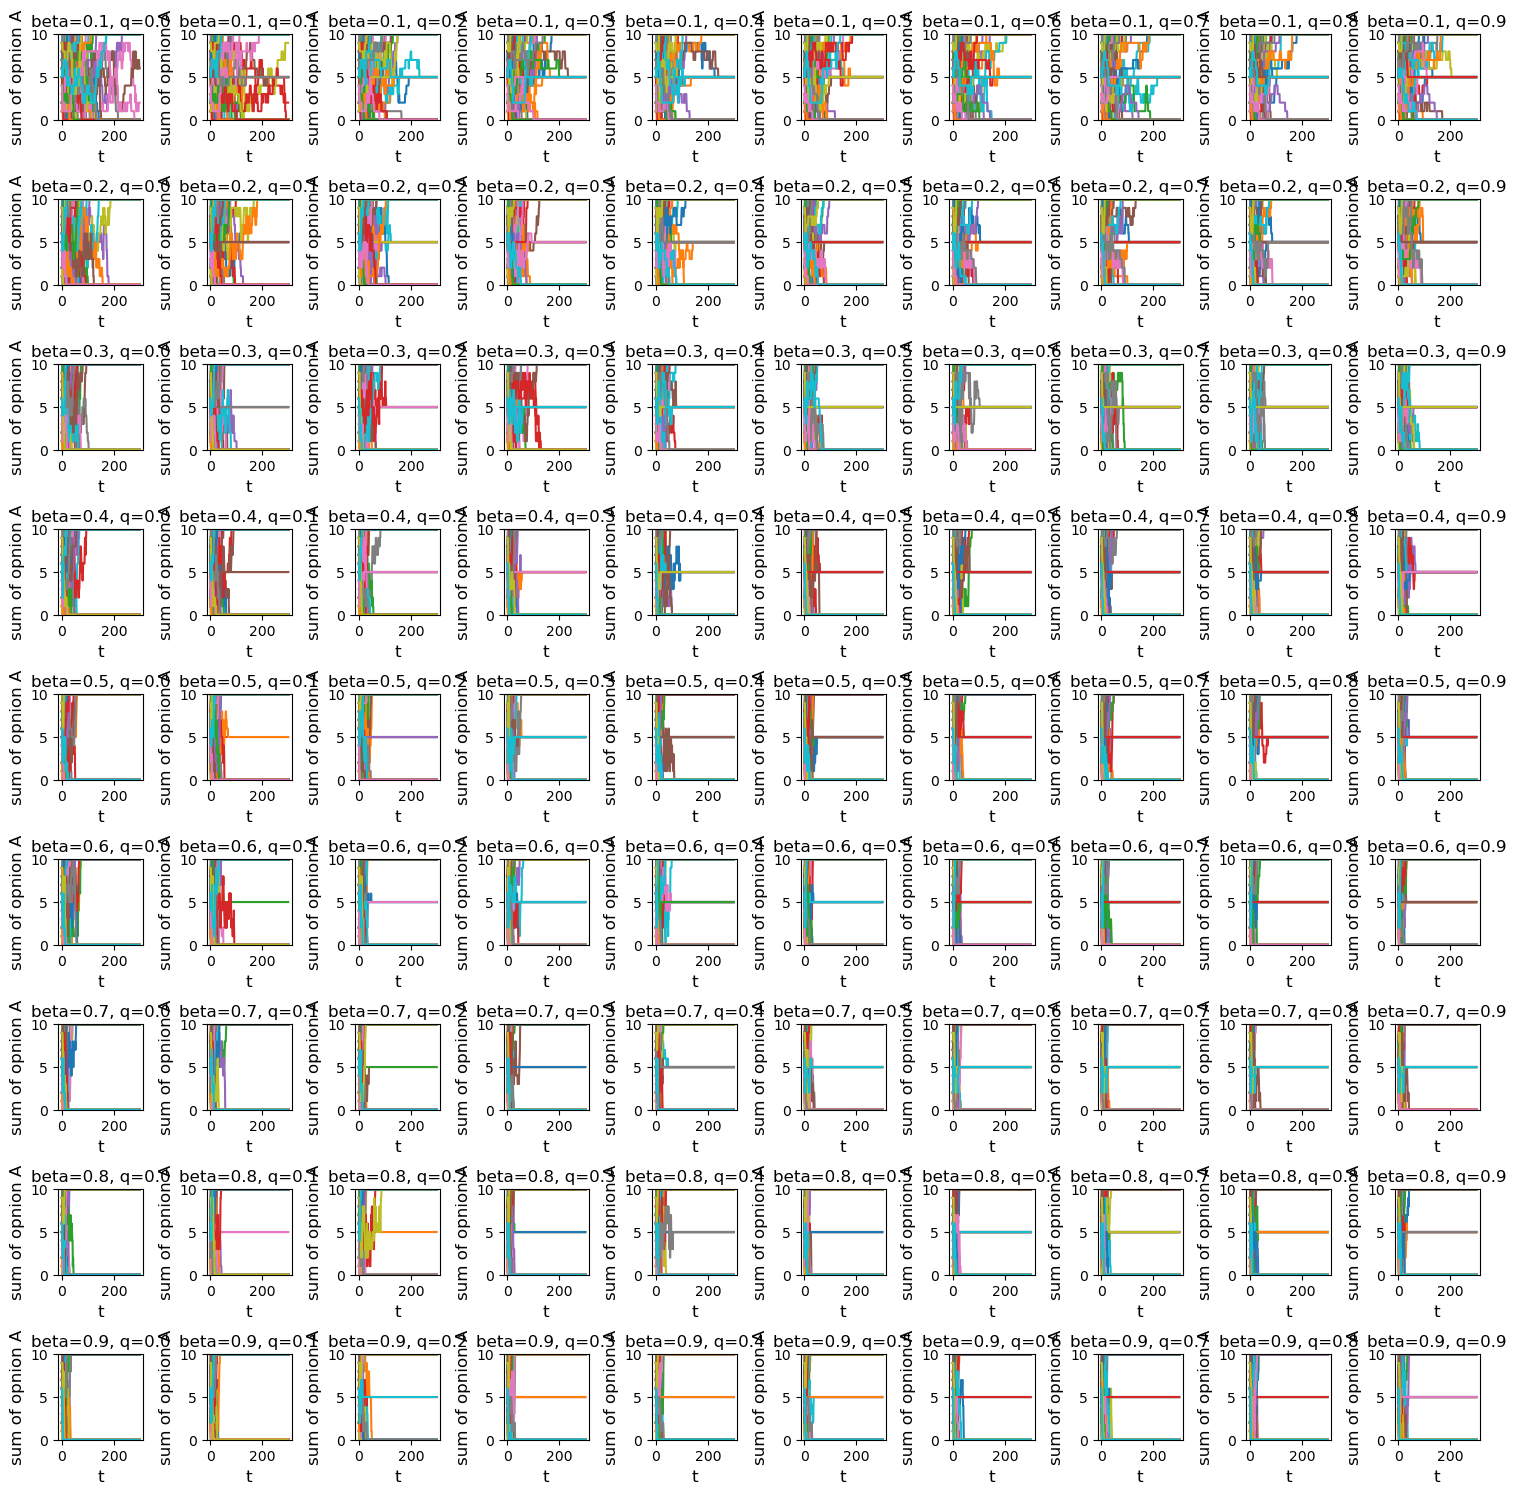

In [39]:
fs=12
ts=10
fig, axes = plt.subplots(len(betas),len(qs), figsize=(15,15))
axes=axes.flatten()
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        results=all_res[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(100):
            ax.plot(results['sum_opinion_A'][it][:300])
        ax.set_ylabel('sum of opnion A',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        ax.set_ylim((0,10))
plt.tight_layout()
plt.savefig('figures/sum_of_A_majority.pdf')
plt.show()
        


In [36]:
len(all_res[0][0]['sum_opinion_A'][0])

500

In [70]:
full_win_endstates_counts_perbetas_lin=[]
disjoint_endstates_counts_perbetas_lin=[]
xvals=[]
yvals=[]
for i in range(len(betas)):
    for j in range(len(qs)):
        xvals.append(betas[i])
        yvals.append(qs[j])
        full_win_endstates_counts_perbetas_lin.append(0)
        disjoint_endstates_counts_perbetas_lin.append(0)
        results=all_res[i][j]
        for it in range(len(results['sum_opinion_A'])):
            if results['sum_opinion_A'][it][-1]%10 ==0:
                full_win_endstates_counts_perbetas_lin[-1]+=1
            else:
                disjoint_endstates_counts_perbetas_lin[-1]+=1

In [22]:
import matplotlib.tri as tri
import numpy as np
import matplotlib.pyplot as plt

# Common style settings
legends = 25
ticks = 20
labels = 30
titles = 35
ngridx, ngridy = 50, 50
np.random.seed(0)

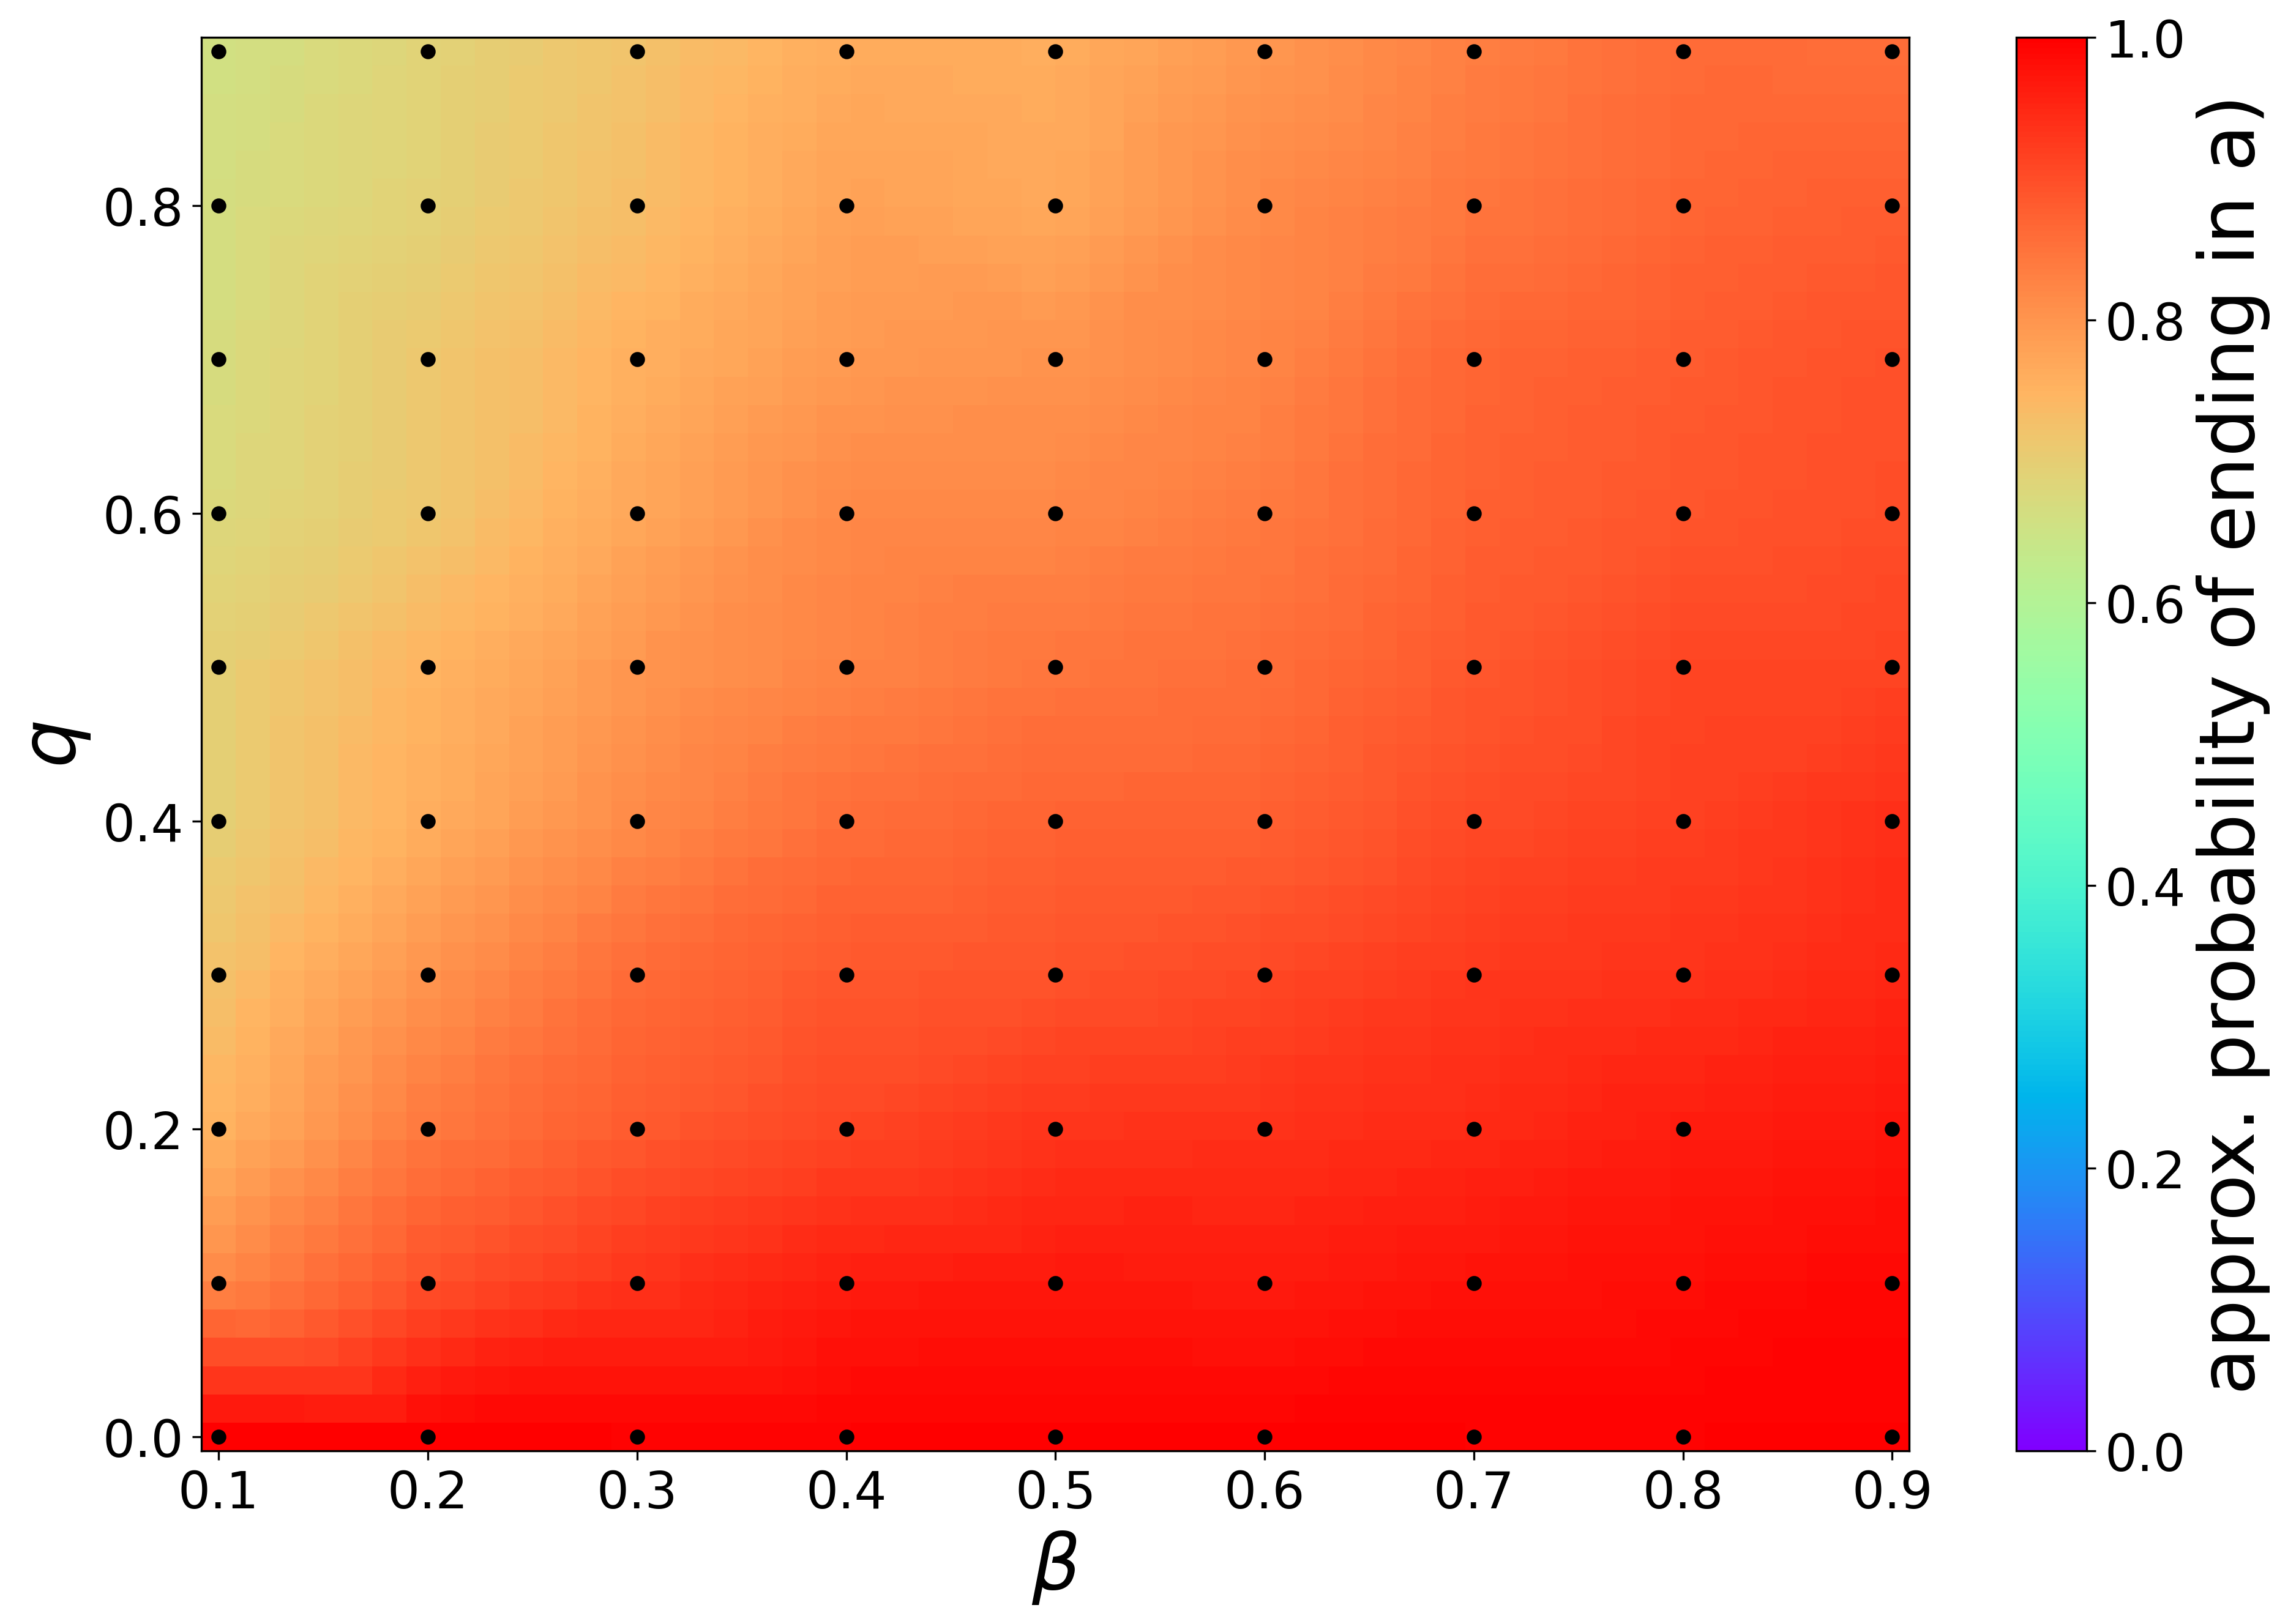

In [41]:
# What is the probability of endingin a) full win of an opinion in the colony. b) two separated homogen household.
# We can show this with a countour plot running a massive number of simulations and count that out of 100 simulation
# process how many ends in a) or b) absorbing states.
# Example data placeholders (replace with your actual arrays)
x = xvals
y = yvals
z = np.array(full_win_endstates_counts_perbetas)/1000


# Interpolation grid
xi = np.linspace(np.min(x), np.max(x), ngridx)
yi = np.linspace(np.min(y), np.max(y), ngridy)
Xi, Yi = np.meshgrid(xi, yi)

fig,ax = plt.subplots(1, 1, figsize=(15, 10), dpi=300)
triang = tri.Triangulation(x, y)
interpolator = tri.LinearTriInterpolator(triang, z)
zi = interpolator(Xi, Yi)

pcm = ax.pcolormesh(xi, yi, zi, vmin=0, vmax=1, shading='auto', cmap='rainbow')
ax.scatter(x, y, c='k',linewidths=2, edgecolors='k', s=15,
               cmap=RedtoBlue_cmap, vmin=0, vmax=1,)

#ax.set_title(, fontsize=titles)
ax.set_xlabel(r'$\beta$', fontsize=labels)
ax.set_ylabel(r'$q$', fontsize=labels)
ax.tick_params(axis='both', labelsize=ticks)
ax.text(-0.06, 1, '', transform=ax.transAxes, va='top', ha='right', fontsize=labels)

# Colorbar
cbar = fig.colorbar(pcm, ax=ax, orientation='vertical')
cbar.ax.tick_params(labelsize=ticks)
cbar.set_label(label=r'approx. probability of ending in a)', fontsize=labels)
#plt.savefig(f"figures/gammavskappa_multiplex_{j}.png", bbox_inches='tight')
plt.show()

In [55]:
# Create a new colormap for the lines
line_colors = ['#d8c264','#cf5c4c'] # Dark red to light yellow
line_cmap = LinearSegmentedColormap.from_list("line_colors", line_colors)


# Get colors from the colormap for the lines
colors = line_cmap(np.linspace(0, 1, 5))
markers = ['o', 's', 'v', '^', 'D'] 

In [102]:
list(5)

TypeError: 'int' object is not iterable

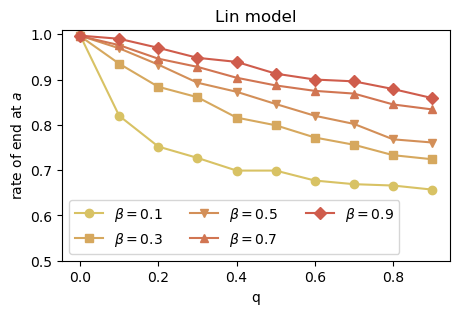

In [62]:
plt.figure(figsize=(5,3))
plt.title('Lin model')
j=0
for i in range(0,len(betas),2):
    plt.plot(qs,np.array(full_win_endstates_counts_perbetas[i*len(qs):(i+1)*len(qs)])/1000,label=r'$\beta=$'+f'{betas[i]:.1f}',marker=markers[j], color=colors[j])
    j+=1

plt.ylim(0.5,1.01)
plt.ylabel('rate of end at $a$')
plt.xlabel('q')
plt.legend(ncol=3)
plt.show()

In [47]:
(1/5+0.5*1)/1.5

0.6

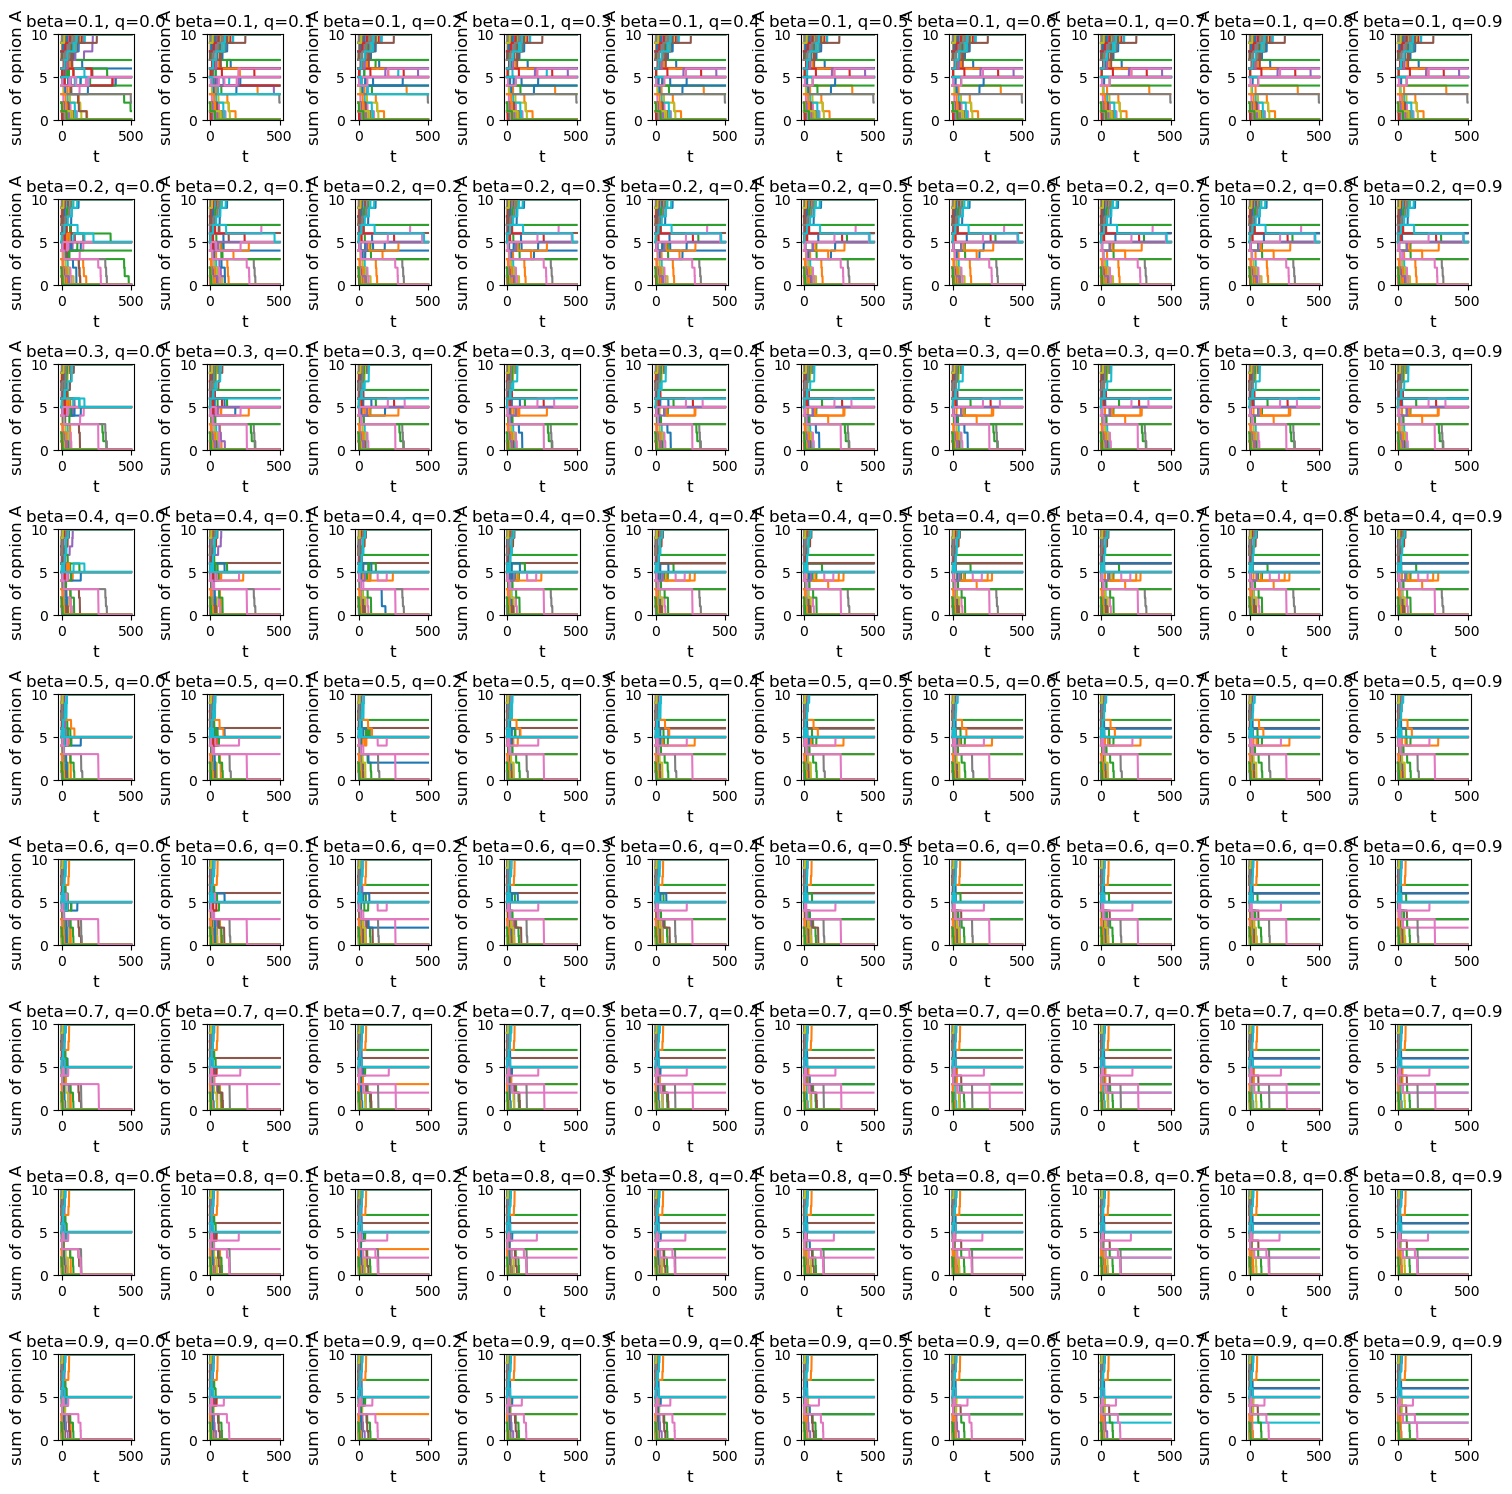

In [77]:
fs=12
ts=10
fig, axes = plt.subplots(len(betas),len(qs), figsize=(15,15))
axes=axes.flatten()
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        results=all_res_nonlin[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(100):
            ax.plot(results['sum_opinion_A'][it][:500])
        ax.set_ylabel('sum of opnion A',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        ax.set_ylim((0,10))
plt.tight_layout()
plt.savefig('figures/sum_of_A_majority.pdf')
plt.show()
        

In [67]:
full_win_endstates_counts_perbetas=[]
mixed_endstates_counts_perbetas=[]
two_homo_hh_homowp=[]
two_homo_hh_nonhomowp=[]
for i in range(0,len(betas)):
    full_win_endstates_counts_perbetas.append(np.zeros(len(qs)))
    mixed_endstates_counts_perbetas.append(np.zeros(len(qs)))
    two_homo_hh_homowp.append(np.zeros(len(qs)))
    two_homo_hh_nonhomowp.append(np.zeros(len(qs)))
    for j in range(0,len(qs)):
        results=all_res_nonlin[i][j]
        for it in range(len(results['sum_opinion_A'])):
            if results['sum_opinion_A'][it][-1]%10 ==0:
                full_win_endstates_counts_perbetas[-1][j]+=1
            elif results['binned_opinions_home'][0][it][-1]+results['binned_opinions_home'][-1][it][-1] != 2:
                mixed_endstates_counts_perbetas[-1][j]+=1
            else:
                if results['binned_opinions_wp'][0][it][-1]+results['binned_opinions_wp'][-1][it][-1] != 2:
                    two_homo_hh_nonhomowp[-1][j]+=1
                else:
                    two_homo_hh_homowp[-1][j]+=1
                #print([results['binned_opinions_wp'][k][it][-1] for k in range(10)], results['sum_opinion_A'][it][-1])

In [63]:
results['binned_opinions_home'][0][0][-1]

1

<function matplotlib.pyplot.show(close=None, block=None)>

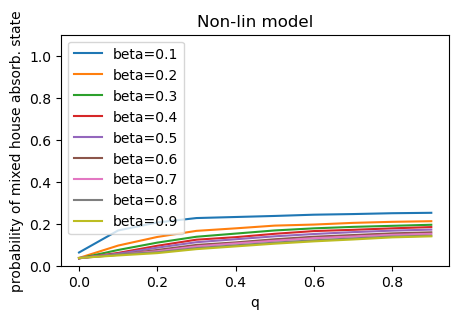

In [75]:
plt.figure(figsize=(5,3))
plt.title('Non-lin model')
for i in range(0,len(betas)):
    plt.plot(qs,mixed_endstates_counts_perbetas[i]/1000,label=f'beta={betas[i]:.1f}')
plt.ylim(0,1.1)
plt.ylabel('probability of mixed house absorb. state')
plt.xlabel('q')
plt.legend()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

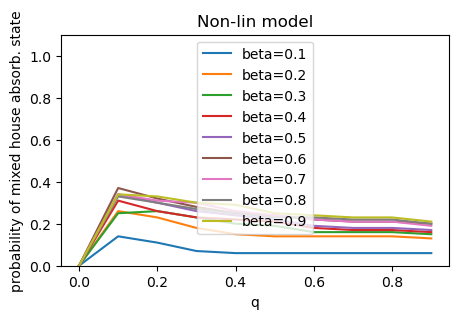

In [198]:
plt.figure(figsize=(5,3))
plt.title('Non-lin model')
for i in range(0,len(betas)):
    plt.plot(qs,two_homo_hh_homowp[i]/100,label=f'beta={betas[i]:.1f}')
plt.ylim(0,1.1)
plt.ylabel('probability of homogen house absorb. state')
plt.xlabel('q')
plt.legend()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

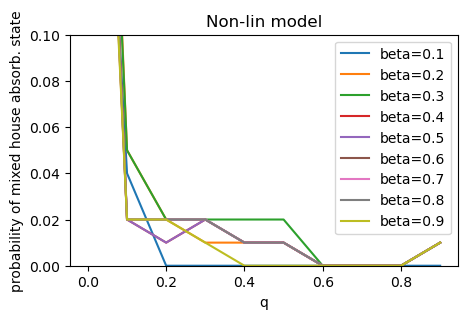

In [200]:
plt.figure(figsize=(5,3))
plt.title('Non-lin model')
for i in range(0,len(betas)):
    plt.plot(qs,two_homo_hh_nonhomowp[i]/100,label=f'beta={betas[i]:.1f}')
plt.ylim(0,0.1)
plt.ylabel('probability of mixed house absorb. state')
plt.xlabel('q')
plt.legend()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

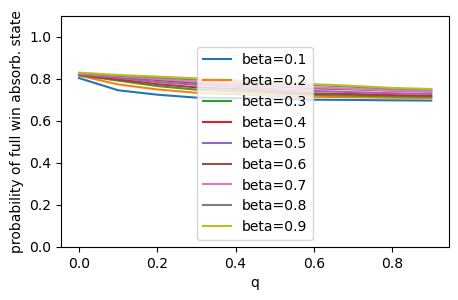

In [76]:
plt.figure(figsize=(5,3))
for i in range(0,len(betas)):
    plt.plot(qs,full_win_endstates_counts_perbetas[i]/1000,label=f'beta={betas[i]:.1f}')
plt.ylim(0,1.1)
plt.ylabel('probability of full win absorb. state')
plt.xlabel('q')
plt.legend()
plt.show

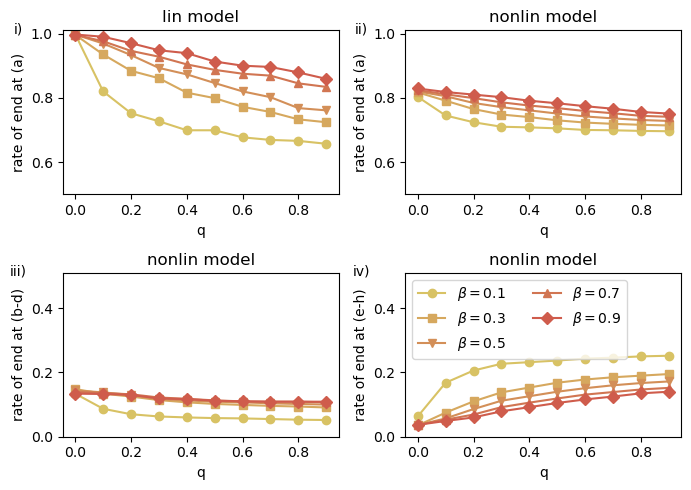

In [115]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(7, 5))  # 4 subplots in one row
axes=axes.flatten()
# --- First subplot: Lin model ---
axes[0].set_title('lin model')
j = 0
for i in range(0, len(betas), 2):
    axes[0].plot(qs,
                 np.array(full_win_endstates_counts_perbetas_lin[i*len(qs):(i+1)*len(qs)]) / 1000,
                 label=rf'$\beta={betas[i]:.1f}$',
                 marker=markers[j], color=colors[j])
    j += 1
axes[0].set_ylim(0.5, 1.01)
axes[0].set_ylabel('rate of end at (a)')
axes[0].set_xlabel('q')
#axes[0].legend(ncol=3)


# --- Second subplot ---
axes[1].set_title('nonlin model')
j = 0
for i in range(0, len(betas), 2):
    axes[1].plot(qs,
                 full_win_endstates_counts_perbetas[i] / 1000,
                 label=rf'$\beta={betas[i]:.1f}$',
                 marker=markers[j], color=colors[j])
    j+=1
axes[1].set_ylim(0.5, 1.01)
axes[1].set_ylabel('rate of end at (a)')
axes[1].set_xlabel('q')
#axes[1].legend(fontsize=8)

# --- Third subplot: Non-lin model ---
axes[3].set_title('nonlin model')
j = 0
for i in range(0, len(betas), 2):
    axes[3].plot(qs,
                 mixed_endstates_counts_perbetas[i] / 1000,
                 label=rf'$\beta={betas[i]:.1f}$',
                 marker=markers[j], color=colors[j])
    j+=1
axes[3].set_ylim(0, 0.51)
axes[3].set_ylabel('rate of end at (e-h)')
axes[3].set_xlabel('q')
#axes[2].legend()

# --- Fourth subplot: Non-lin model ---
axes[2].set_title('nonlin model')
j = 0
for i in range(0, len(betas), 2):
    axes[2].plot(qs,
                 (two_homo_hh_homowp[i] +  two_homo_hh_nonhomowp[i])/ 1000,
                 label=rf'$\beta={betas[i]:.1f}$',
                 marker=markers[j], color=colors[j])
    j+=1
axes[2].set_ylim(0, 0.51)
axes[2].set_ylabel('rate of end at (b-d)')
axes[2].set_xlabel('q')
axes[3].legend(ncol=2)

axes[0].text(-0.16, 1.05, 'i)', transform=axes[0].transAxes,ha='center' ,va='top')
axes[1].text(-0.16, 1.05, 'ii)', transform=axes[1].transAxes,ha='center', va='top')
axes[3].text(-0.16, 1.05, 'iv)', transform=axes[3].transAxes,ha='center', va='top')
axes[2].text(-0.16, 1.05, 'iii)', transform=axes[2].transAxes,ha='center', va='top')


plt.tight_layout()

plt.savefig('figures/rate_absorb.pdf')
plt.show()


In [ ]:
x=np.linspace(0,1,20)
plt.plot(x,x*np.exp(1-x))
plt.grid()

IndexError: list index out of range

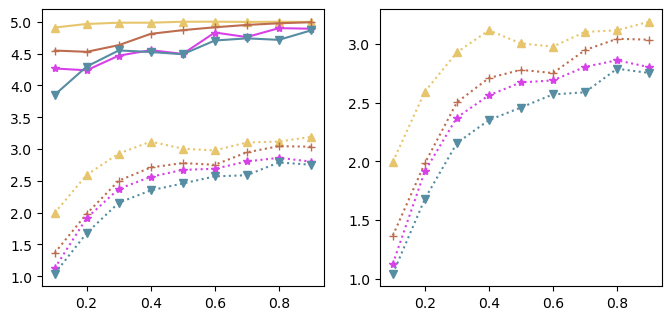

In [21]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
fig,axs = plt.subplots(1,2 ,figsize=(8,3.6))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.std([results['sum_opinion_A'][it][-1] for it in range(iterations)])
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.std([results['sum_opinion_A'][it][-1] for it in range(iterations)])
        x2.append(s)
    axs[0].plot(betas,x1,label=f'q={qs[j]:.1f} lin',marker=markers[j], color=colors[j])
    axs[0].plot(betas,x2,label=f'q={qs[j]:.1f} nonlin',marker=markers[j], color=colors[j], ls='dotted')
    axs[1].plot(betas,x2,label=f'q={qs[j]:.1f} nonlin',marker=markers[j], color=colors[j], ls='dotted')

axs[0].set_xlabel(r'$\beta$', fontsize=15)
axs[1].set_xlabel(r'$\beta$', fontsize=15)
axs[0].set_ylabel(r'$\sigma(N_A)$', fontsize=15)
axs[0].set_ylim(0,10)

hs=[]
line = mlines.Line2D([], [], color='k', label=r'lin r=1')
hs.append(line)
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color='k',linestyle='dotted', label=r'non-lin r=0.5')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/std.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=150)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

In [156]:
all_res[8][0]['binned_opinions_wp'][9][0][-1]

19

In [124]:
axs

array([<AxesSubplot:>, <AxesSubplot:>], dtype=object)

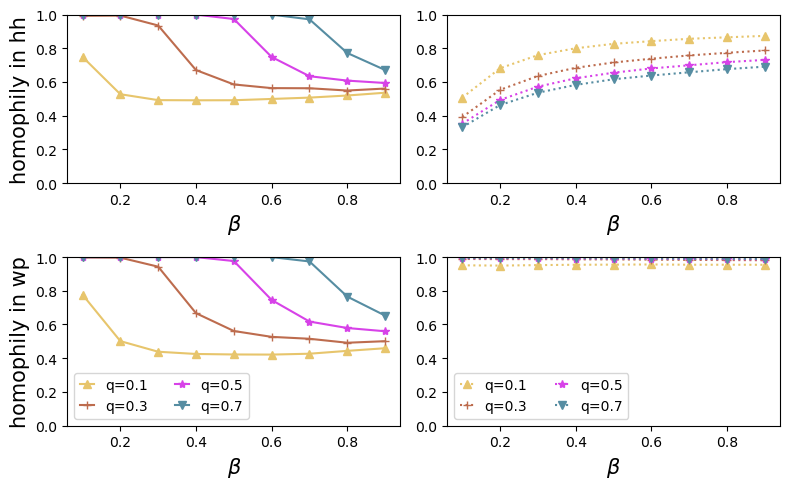

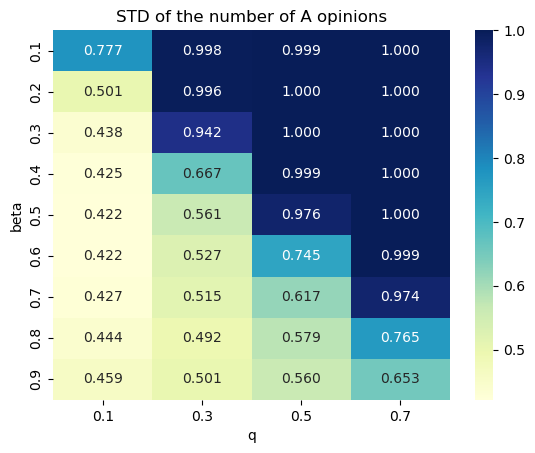

In [15]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([(results['binned_opinions_home'][0][it][-1]+results['binned_opinions_home'][5][it][-1])/200 for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([(results['binned_opinions_home'][0][it][-1]+results['binned_opinions_home'][5][it][-1])/200 for it in range(iterations)])
        x2.append(s)
    axs[0][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[0][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[0][0].set_xlabel(r'$\beta$', fontsize=15)
axs[0][1].set_xlabel(r'$\beta$', fontsize=15)
axs[0][0].set_ylabel(r'homophily in hh', fontsize=15)
axs[0][0].set_ylim(0,1)
axs[0][1].set_ylim(0,1)

markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([(results['binned_opinions_wp'][0][it][-1]+results['binned_opinions_wp'][9][it][-1])/200 for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([(results['binned_opinions_wp'][0][it][-1]+results['binned_opinions_wp'][9][it][-1])/200 for it in range(iterations)])
        x2.append(s)
    axs[1][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[1][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[1][0].set_xlabel(r'$\beta$', fontsize=15)
axs[1][1].set_xlabel(r'$\beta$', fontsize=15)
axs[1][0].set_ylabel(r'homophily in wp', fontsize=15)
axs[1][0].set_ylim(0,1)
axs[1][1].set_ylim(0,1)

hs=[]
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/hom_index.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=1)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

In [169]:
np.where(np.array([False,True,False]))[0][0]

1

In [188]:
np.mean([np.where(((np.array(all_res[i][j]['binned_opinions_home'][0][it])+np.array(all_res[i][j]['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(all_res[i][j]['binned_opinions_wp'][0][it][-10:])+np.array(all_res[i][j]['binned_opinions_wp'][9][it][-10:]))/200)-0.1))[0][0] for it in range(iterations)])


60.29

In [176]:
np.where(((np.array(all_res[i][j]['binned_opinions_home'][0][it])+np.array(all_res[i][j]['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(all_res[i][j]['binned_opinions_wp'][0][it][-5:])+np.array(all_res[i][j]['binned_opinions_wp'][9][it][-5:]))/200)-0.05))[0][0]

67

In [175]:
(np.array(all_res[i][j]['binned_opinions_home'][0][it])+np.array(all_res[i][j]['binned_opinions_home'][5][it]))/200

array([0.06 , 0.065, 0.1  , 0.11 , 0.105, 0.115, 0.15 , 0.165, 0.165,
       0.19 , 0.2  , 0.23 , 0.235, 0.265, 0.28 , 0.29 , 0.3  , 0.31 ,
       0.32 , 0.33 , 0.335, 0.345, 0.365, 0.395, 0.39 , 0.38 , 0.38 ,
       0.36 , 0.385, 0.4  , 0.42 , 0.415, 0.395, 0.415, 0.415, 0.42 ,
       0.42 , 0.415, 0.44 , 0.435, 0.41 , 0.395, 0.415, 0.435, 0.43 ,
       0.42 , 0.4  , 0.415, 0.435, 0.44 , 0.47 , 0.45 , 0.46 , 0.46 ,
       0.46 , 0.445, 0.425, 0.44 , 0.42 , 0.43 , 0.45 , 0.445, 0.47 ,
       0.47 , 0.49 , 0.49 , 0.495, 0.515, 0.51 , 0.505, 0.505, 0.515,
       0.505, 0.49 , 0.51 , 0.505, 0.515, 0.51 , 0.51 , 0.515, 0.52 ,
       0.52 , 0.51 , 0.51 , 0.505, 0.515, 0.52 , 0.545, 0.545, 0.53 ,
       0.535, 0.545, 0.56 , 0.55 , 0.54 , 0.535, 0.55 , 0.535, 0.52 ,
       0.525])

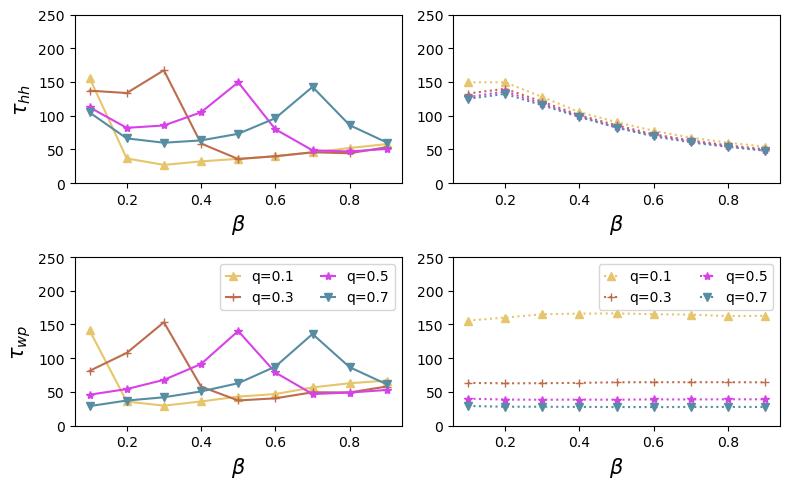

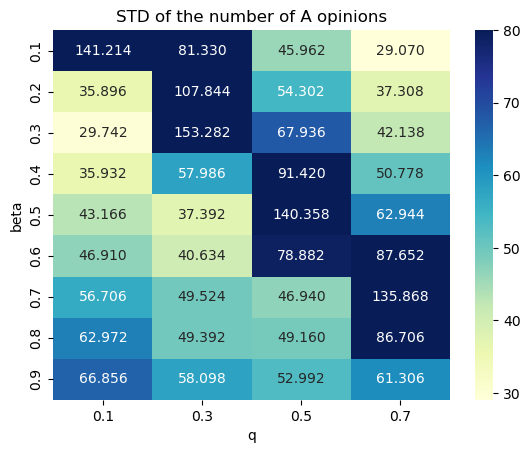

In [18]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
epsilon=0.1

fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(results['binned_opinions_home'][0][it][-5:])+np.array(results['binned_opinions_home'][5][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(results['binned_opinions_home'][0][it][-5:])+np.array(results['binned_opinions_home'][5][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        x2.append(s)
    axs[0][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[0][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[0][0].set_xlabel(r'$\beta$', fontsize=15)
axs[0][1].set_xlabel(r'$\beta$', fontsize=15)
axs[0][0].set_ylabel(r'$\tau_{hh}$', fontsize=15)
axs[0][0].set_ylim(0,250)
axs[0][1].set_ylim(0,250)

markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>(np.mean((np.array(results['binned_opinions_wp'][0][it][-5:])+np.array(results['binned_opinions_wp'][9][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>(np.mean((np.array(results['binned_opinions_wp'][0][it][-5:])+np.array(results['binned_opinions_wp'][9][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        x2.append(s)
    axs[1][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[1][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[1][0].set_xlabel(r'$\beta$', fontsize=15)
axs[1][1].set_xlabel(r'$\beta$', fontsize=15)
axs[1][0].set_ylabel(r'$\tau_{wp}$', fontsize=15)
axs[1][0].set_ylim(0,250)
axs[1][1].set_ylim(0,250)

hs=[]
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/hom_time.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=80)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

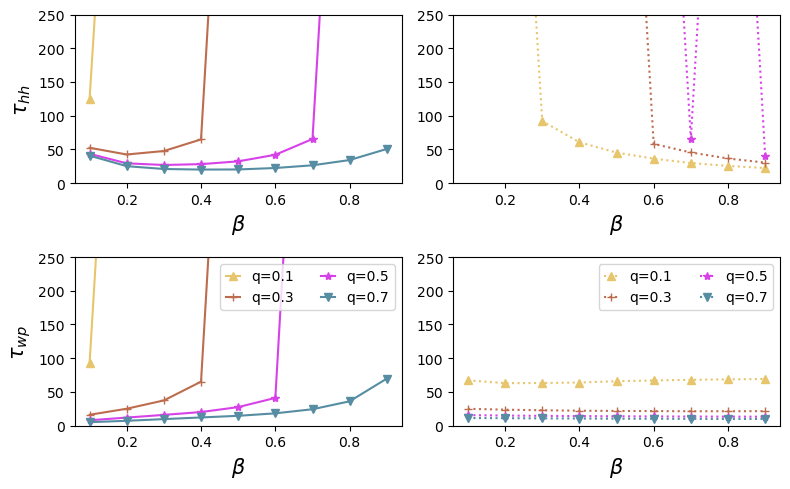

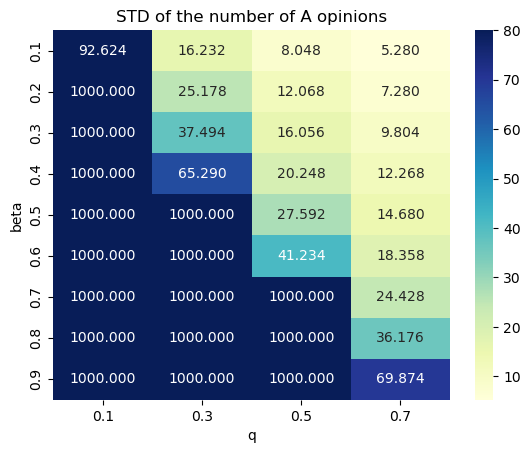

In [29]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
epsilon=0.6

fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        except:
            s = 1000
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        except:
            s = 1000
        x2.append(s)
    axs[0][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[0][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[0][0].set_xlabel(r'$\beta$', fontsize=15)
axs[0][1].set_xlabel(r'$\beta$', fontsize=15)
axs[0][0].set_ylabel(r'$\tau_{hh}$', fontsize=15)
axs[0][0].set_ylim(0,250)
axs[0][1].set_ylim(0,250)

markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        except:
            s = 1000
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        
        except:
            s = 1000
        x2.append(s)
    axs[1][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[1][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[1][0].set_xlabel(r'$\beta$', fontsize=15)
axs[1][1].set_xlabel(r'$\beta$', fontsize=15)
axs[1][0].set_ylabel(r'$\tau_{wp}$', fontsize=15)
axs[1][0].set_ylim(0,250)
axs[1][1].set_ylim(0,250)

hs=[]
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/hom_time.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=80)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

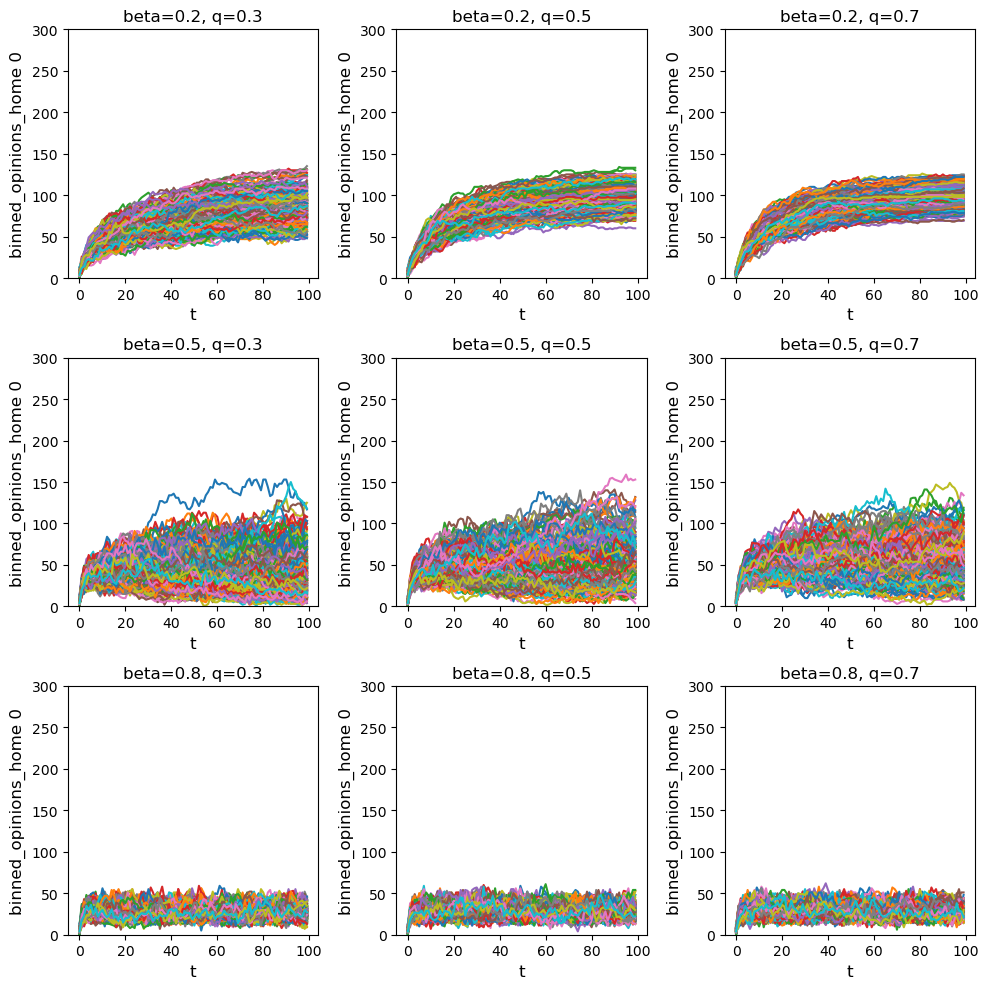

In [45]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['binned_opinions_home'][0][it])
        ax.set_ylabel('binned_opinions_home 0',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        ax.set_ylim((0,300))
plt.tight_layout()

plt.show()
        


In [151]:
for i in range(0,len(betas),6):
    print(betas[i])

0.2
0.49999999999999994
0.7999999999999998


In [23]:
fs=12
ts=10
def hyperedge_opinions(row='binned_opinions_home', color_i=0, typeofedges='home'):
    fig, axes = plt.subplots(len(betas),len(qs), figsize=(15,15))
    axes=axes.flatten()
    k=0
    for i in range(0,len(betas)):
        beta=betas[i]
        for j in range(0,len(qs)):
            results=all_res_nonlin[i][j]
            ax=axes[k]
            
            q=qs[j]
            
            data_mean=[]
            data_error=[]
            print(beta,q)
            ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
            for l in range(len(results[row])):
                data=[results[row][l][it][-1] for it in range(iterations)]
                m =mean_confidence_interval(data,0.95)
                data_mean.append(m[0])
                data_error.append(2*m[1])
            ax.bar(np.arange(len(results[row])), data_mean, 0.8, label=None, color=colors[color_i],edgecolor = 'black',yerr=data_error, capsize=4,)
            # Customize the second subplot
            ax.set_ylim(0,120)
            if typeofedges=='home':
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'# persons on opinion A', fontsize=fs)
                ax.set_xticks(np.arange(len(results[row])))
                
            elif typeofedges=='workplace':
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'rate of persons on opinion A', fontsize=fs)
                ax.set_xticks(np.arange(0,len(results[row]),2), (np.arange(0,len(results[row]),2)+1)/10)
            else:
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'size', fontsize=fs)
                ax.set_xticks(np.arange(len(results[row]))+1)
                ax.set_ylim((0,100))
            ax.tick_params(axis='both', labelsize=ts)# Example categories
            
            k+=1
    plt.tight_layout()

0.1 0.1
0.1 0.30000000000000004
0.1 0.5000000000000001
0.1 0.7000000000000001
0.2 0.1
0.2 0.30000000000000004
0.2 0.5000000000000001
0.2 0.7000000000000001
0.30000000000000004 0.1
0.30000000000000004 0.30000000000000004
0.30000000000000004 0.5000000000000001
0.30000000000000004 0.7000000000000001
0.4 0.1
0.4 0.30000000000000004
0.4 0.5000000000000001
0.4 0.7000000000000001
0.5 0.1
0.5 0.30000000000000004
0.5 0.5000000000000001
0.5 0.7000000000000001
0.6 0.1
0.6 0.30000000000000004
0.6 0.5000000000000001
0.6 0.7000000000000001
0.7000000000000001 0.1
0.7000000000000001 0.30000000000000004
0.7000000000000001 0.5000000000000001
0.7000000000000001 0.7000000000000001
0.8 0.1
0.8 0.30000000000000004
0.8 0.5000000000000001
0.8 0.7000000000000001
0.9 0.1
0.9 0.30000000000000004
0.9 0.5000000000000001
0.9 0.7000000000000001


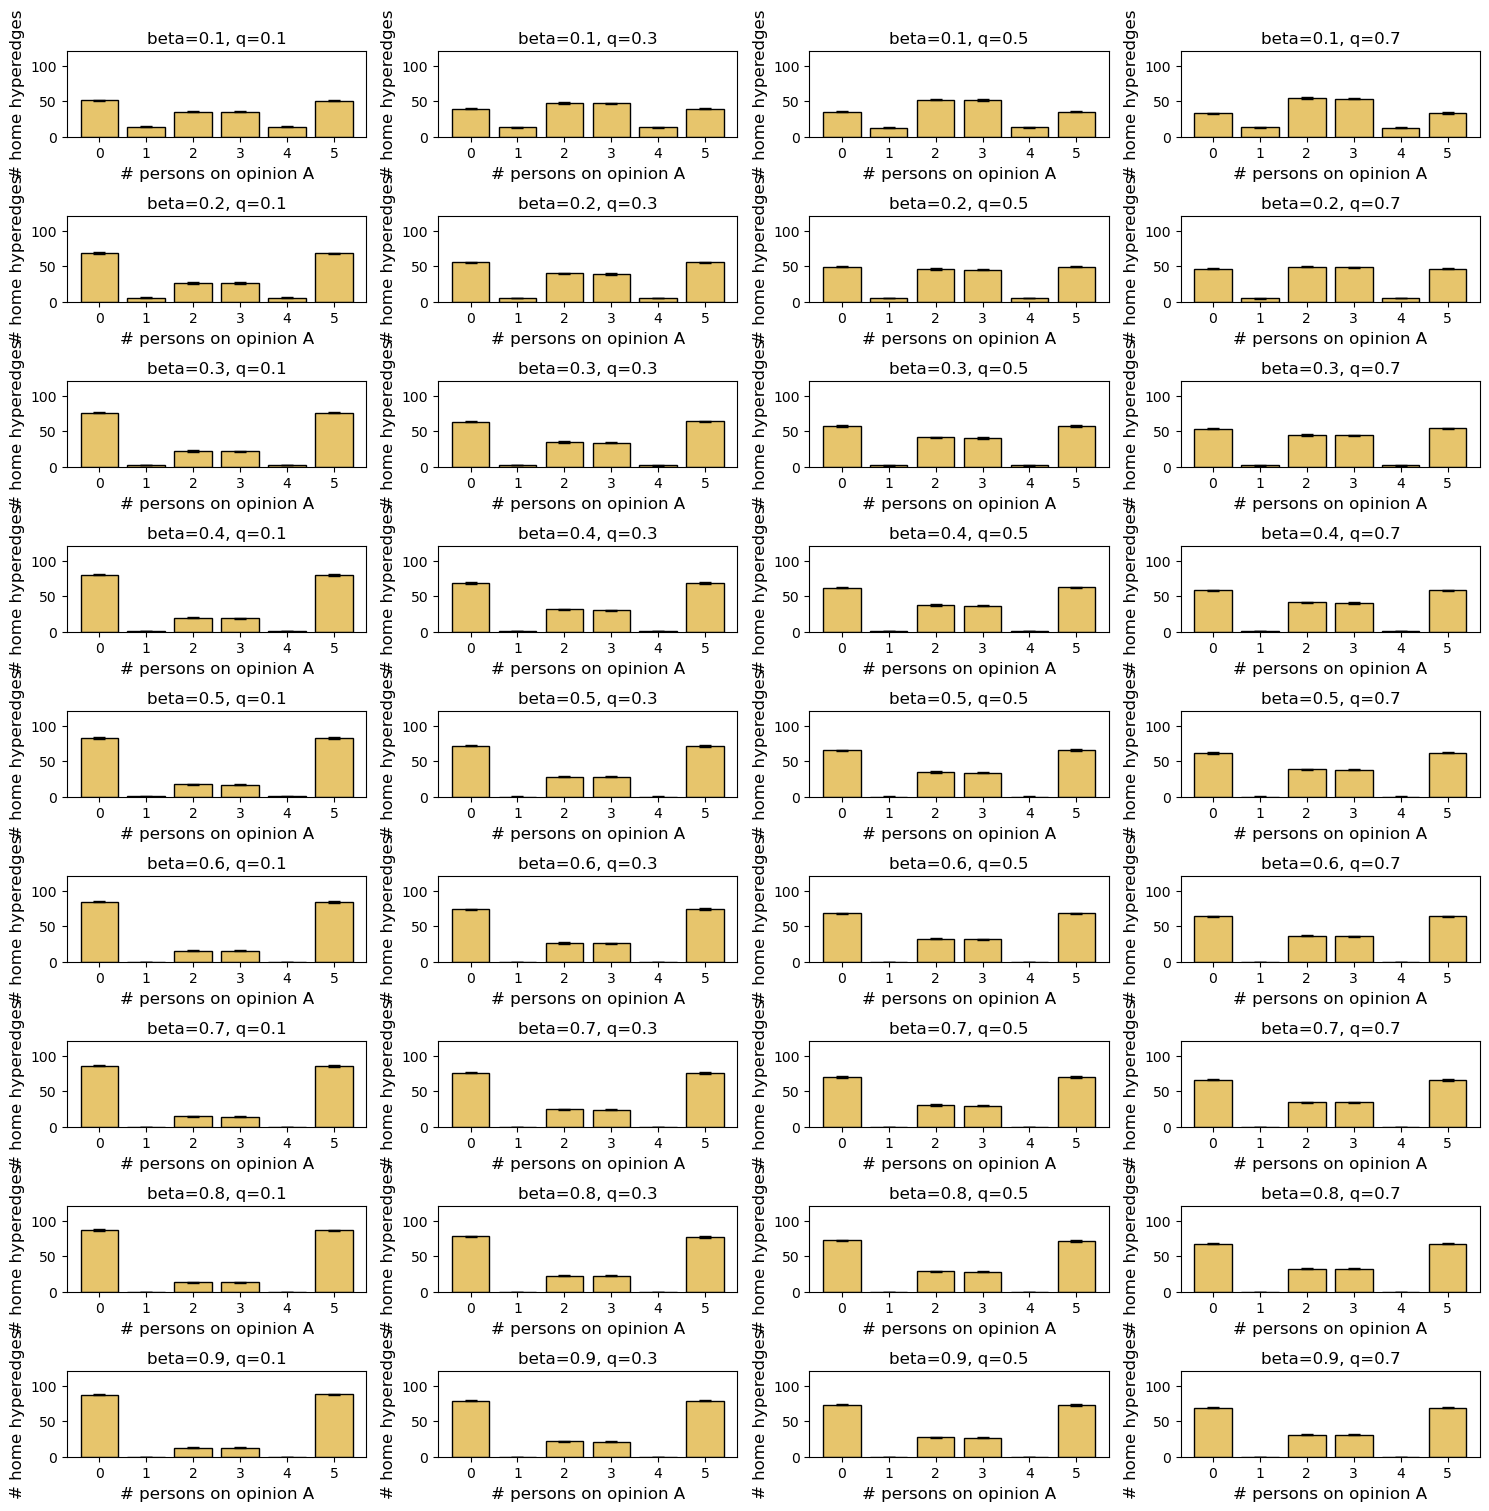

In [24]:
hyperedge_opinions(row='binned_opinions_home', color_i=0)
plt.savefig('figures/binned_opinions_home_majority.pdf')

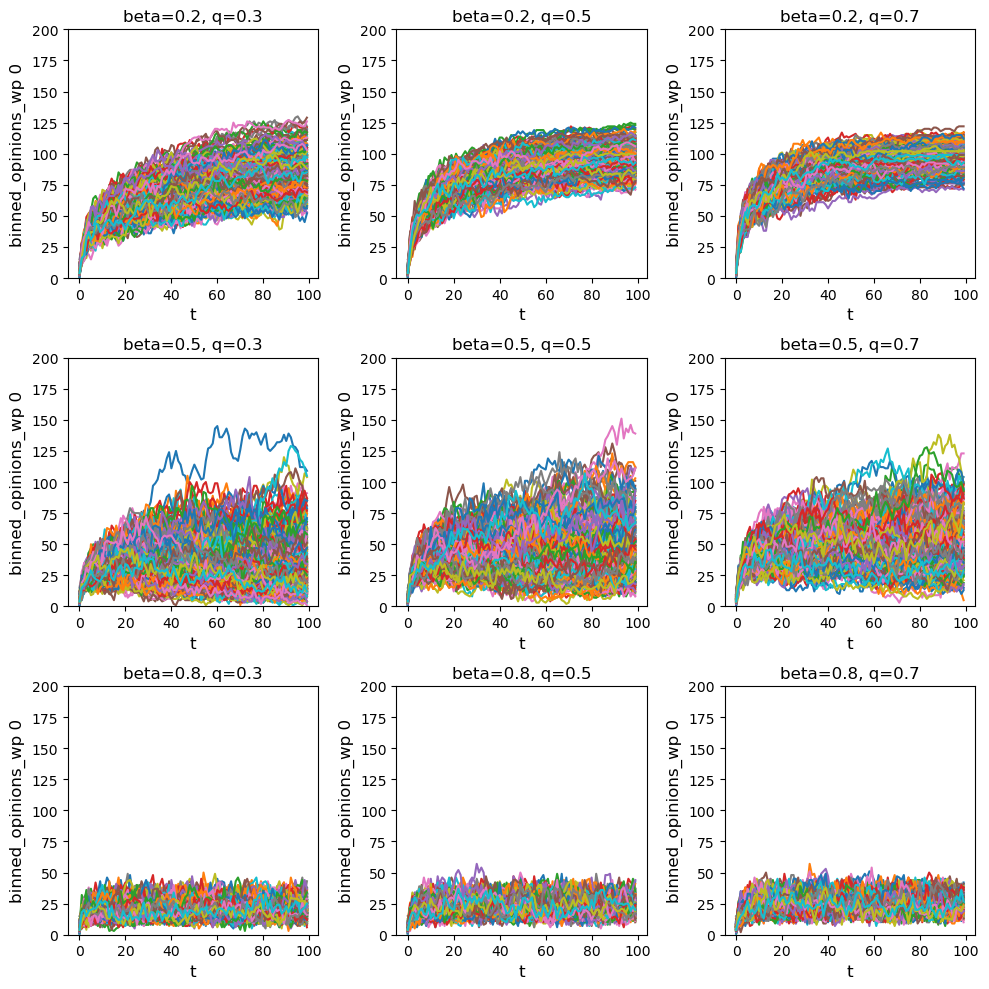

In [43]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['binned_opinions_wp'][0][it])
        ax.set_ylabel('binned_opinions_wp 0',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        ax.set_ylim((0,200))
plt.tight_layout()
plt.show()
        


0.1 0.1
0.1 0.30000000000000004
0.1 0.5000000000000001
0.1 0.7000000000000001
0.2 0.1
0.2 0.30000000000000004
0.2 0.5000000000000001
0.2 0.7000000000000001
0.30000000000000004 0.1
0.30000000000000004 0.30000000000000004
0.30000000000000004 0.5000000000000001
0.30000000000000004 0.7000000000000001
0.4 0.1
0.4 0.30000000000000004
0.4 0.5000000000000001
0.4 0.7000000000000001
0.5 0.1
0.5 0.30000000000000004
0.5 0.5000000000000001
0.5 0.7000000000000001
0.6 0.1
0.6 0.30000000000000004
0.6 0.5000000000000001
0.6 0.7000000000000001
0.7000000000000001 0.1
0.7000000000000001 0.30000000000000004
0.7000000000000001 0.5000000000000001
0.7000000000000001 0.7000000000000001
0.8 0.1
0.8 0.30000000000000004
0.8 0.5000000000000001
0.8 0.7000000000000001
0.9 0.1
0.9 0.30000000000000004
0.9 0.5000000000000001
0.9 0.7000000000000001


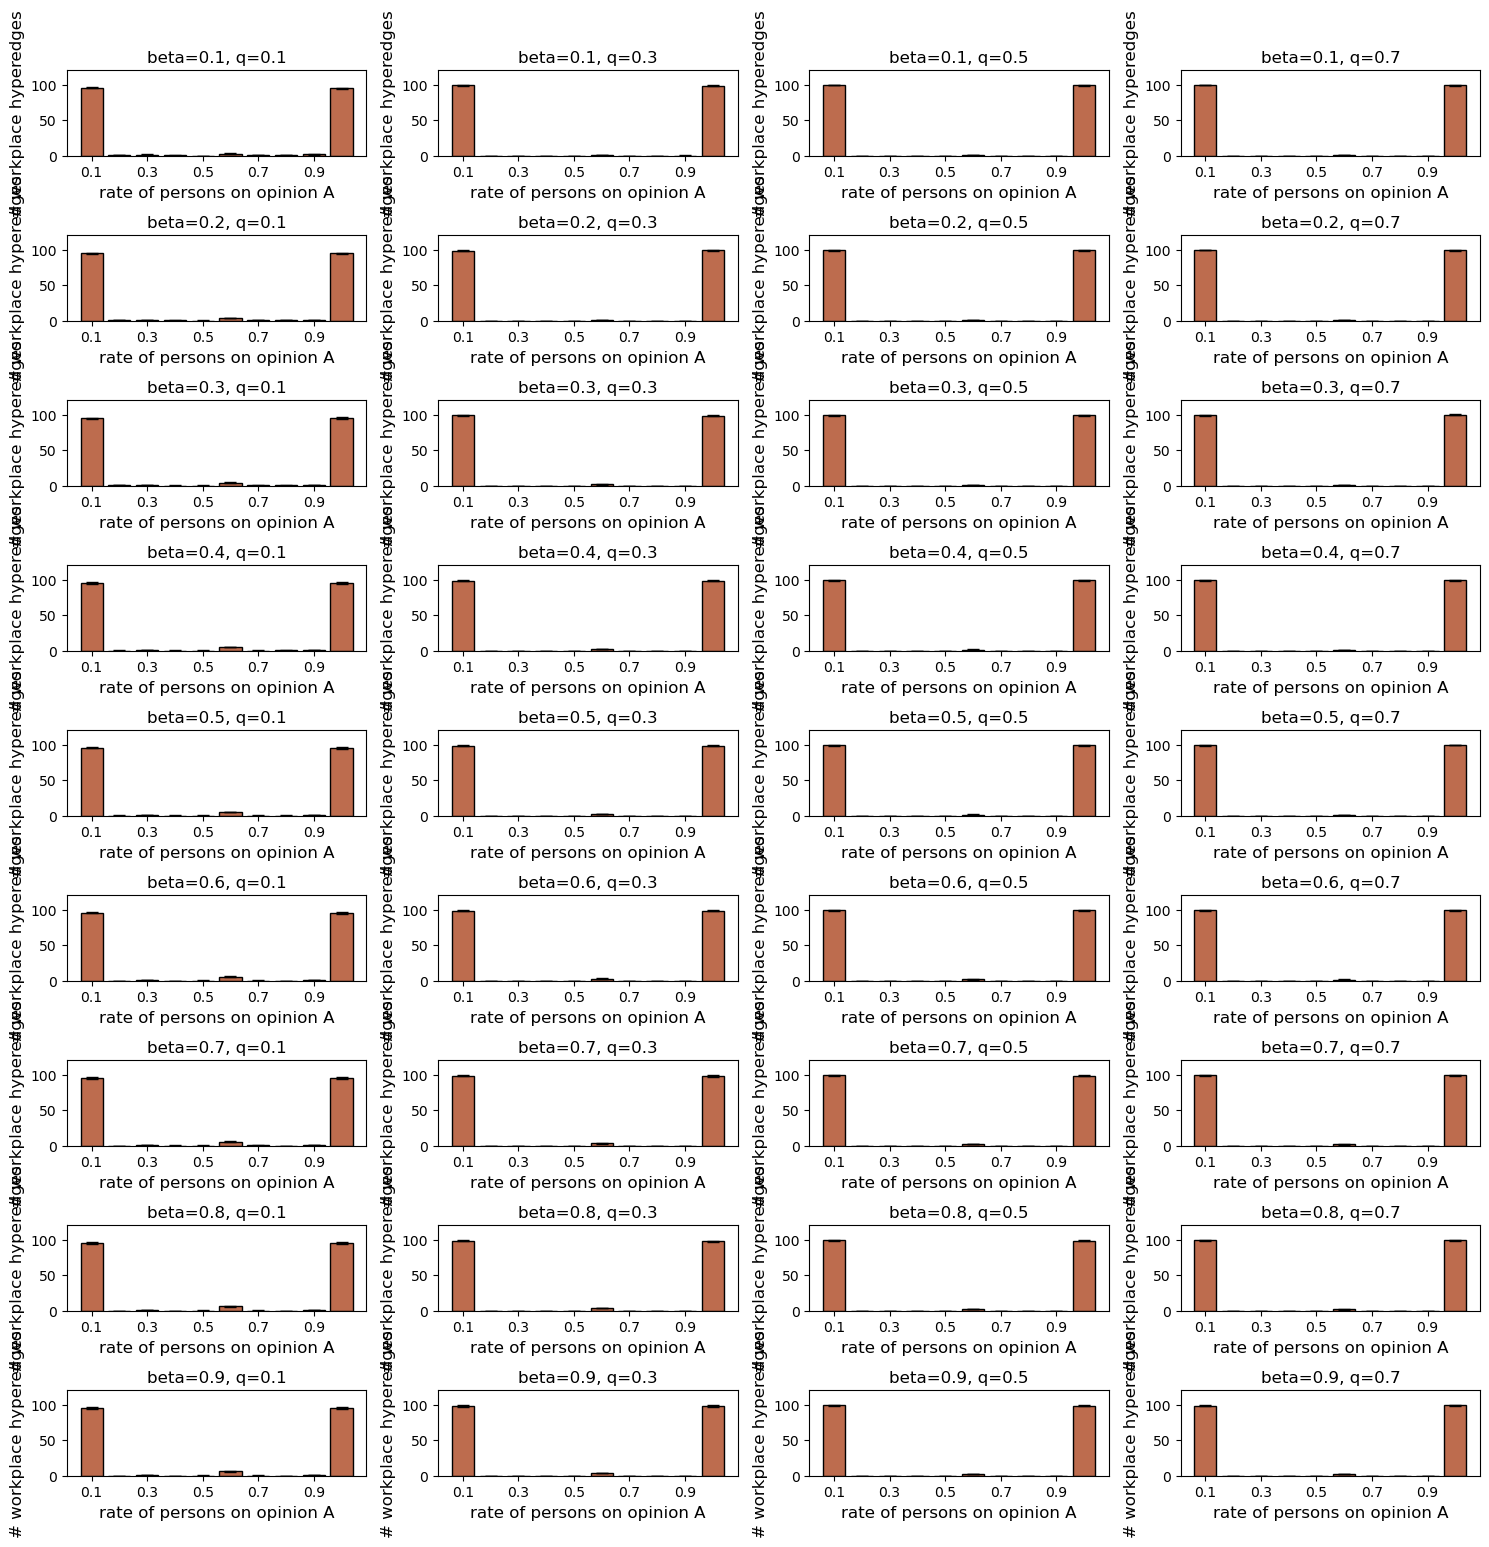

In [25]:
hyperedge_opinions(row='binned_opinions_wp', color_i=1, typeofedges='workplace')
plt.savefig('figures/binned_opinions_wp_majority.pdf')


0.2 0.3
0.2 0.5
0.2 0.7000000000000002
0.49999999999999994 0.3
0.49999999999999994 0.5
0.49999999999999994 0.7000000000000002
0.7999999999999998 0.3
0.7999999999999998 0.5
0.7999999999999998 0.7000000000000002


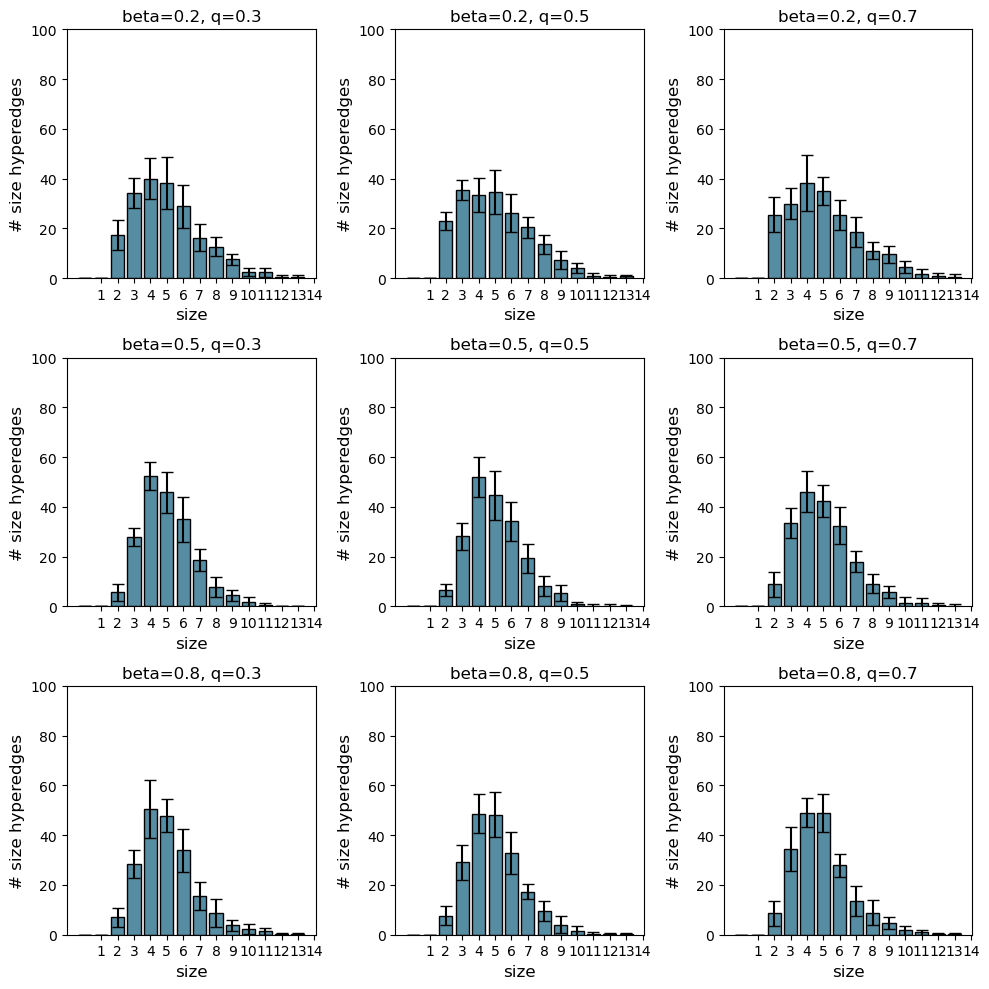

In [63]:
hyperedge_opinions(row='binned_edge_sizes_wp', color_i=2, typeofedges='size')
plt.savefig('figures/binned_edge_sizes_wp_majority.pdf')

In [54]:
data_home ="data/majority_move2/"

In [59]:
all_res2[0][0].keys()

dict_keys(['sum_opinion_A', 'binned_opinions_home', 'binned_opinions_wp', 'binned_edge_sizes_wp', 'move_count', 'op_change_count'])

In [56]:
betas=np.arange(0.2,1.05,0.05)
qs=np.arange(0.3,0.8,0.1)
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp', 'move_count', 'op_change_count']
iterations=10

all_res2 = []
for beta_i, beta in enumerate(betas):
    all_res2.append([])
    for q_i,q in enumerate(qs):
        beta_str=str(np.round(beta, 2)).replace('.', '')
        q_str=str(np.round(q, 1)).replace('.', '')
        filename = f"2_regular_edgesize_5_maj_change_beta_{beta_str}_q_{q_str}.csv"
        df = pd.read_csv(data_home + filename)
        
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            if row != 'sum_opinion_A':
                pdrow=list(df.iloc[[row_i]].values[0])
                for j in range(len(pdrow[2].split(' '))):
                        results[row].append([])
            for i in range(iterations):
                pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
                if row != 'sum_opinion_A':
                    for j,k in enumerate(pdrow[2].split(' ')):
                        results[row][j].append([])
                    for item in pdrow[2:-1]:
                        for j,k in enumerate(item.split(' ')):
                            results[row][j][i].append(int(k))
                else:
                    try:
                        results[row].append([int(item)for item in pdrow[2:-1]])
                    except:
                        print(i)
                        break
        all_res2[beta_i].append(results)

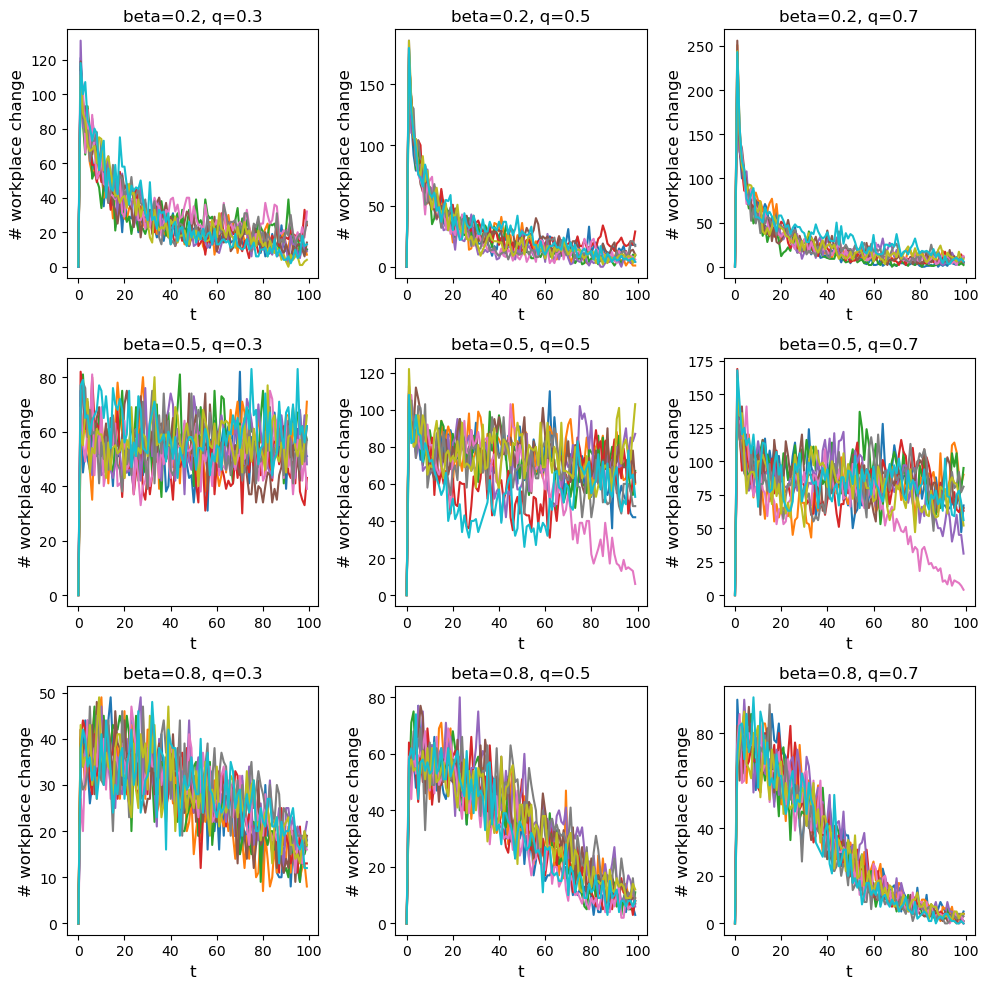

In [65]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res2[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['move_count'][0][it])
        ax.set_ylabel('# workplace change',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        #ax.set_ylim()
plt.tight_layout()
plt.show()
        

In [ ]:
, 'op_change_count'

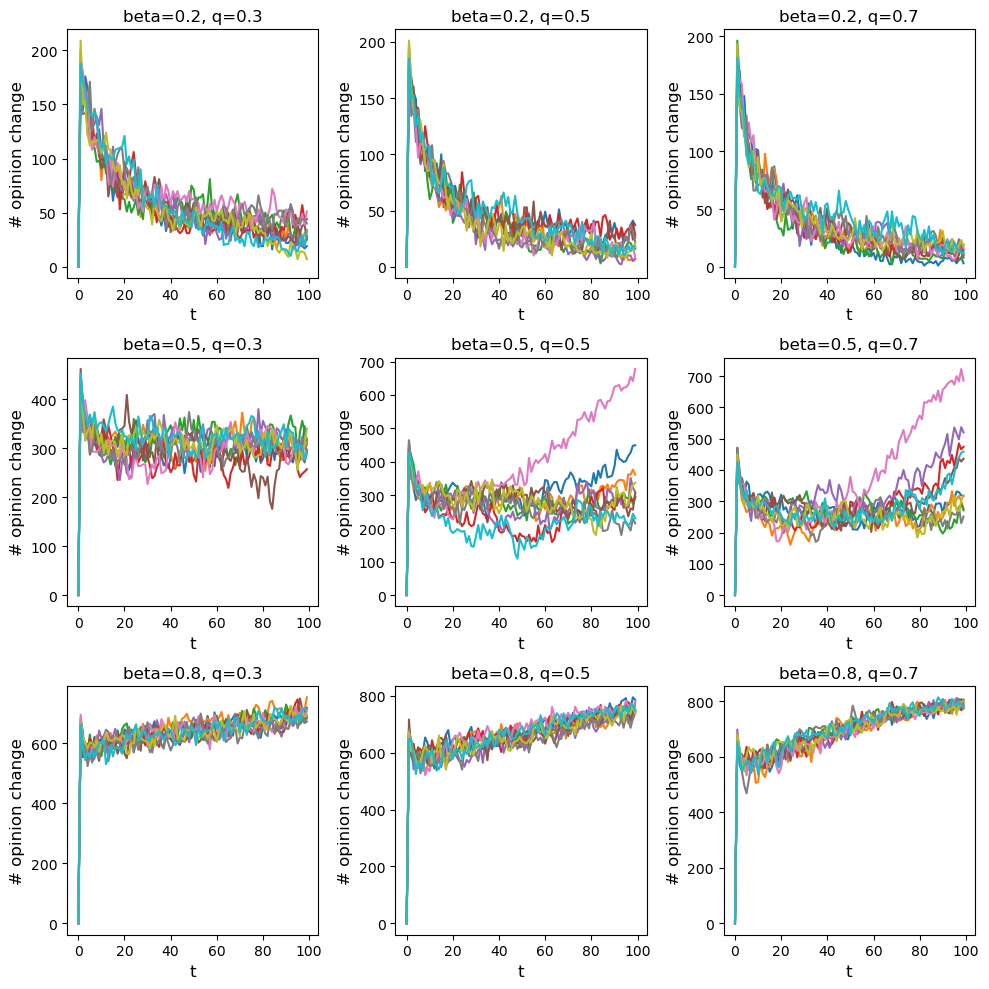

In [66]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res2[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['op_change_count'][0][it])
        ax.set_ylabel('# opinion change',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        #ax.set_ylim()
plt.tight_layout()
plt.show()
        

In [153]:
def mean_field_dynamics(s,w,beta=0.5, q=0.2, steps=200, tol=1e-6):
    # Initial probability vectors

    n = len(s)
    household_size = 5
    history = [[s.copy(), w.copy()]]

    def get_household(v):
        return range(0, 5) if v < 5 else range(5, 10)

    for step in range(steps):
        s_new = s.copy()
        w_new = w.copy()

        norm_w = np.sum(w)
        norm_1w = np.sum(1 - w)
        norm_w = max(norm_w, 1e-6)  # avoid division by zero
        norm_1w = max(norm_1w, 1e-6)

        for v in range(n):
            # --- Opinion dynamics update ---
            household = get_household(v)

            household_term = sum(s[u] - s[v] for u in household) / household_size

            workplace_term = 0
            for u in range(n):
                sim = (w[u] * w[v]) / norm_w + ((1 - w[u]) * (1 - w[v])) / norm_1w
                workplace_term += sim * (s[u] - s[v])
            workplace_term /= household_size

            s_new[v] = s[v] + beta * (2/3 * household_term + 1/3 * workplace_term)

        for v in range(n):
            # --- Edge dynamics update ---
            delta_w = 0
            for u in range(n):
                diff = s[u] * (1 - s[v]) + (1 - s[u]) * s[v]
                sim = -(w[u] * w[v]) / norm_w + ((1 - w[u]) * (1 - w[v])) / norm_1w
                delta_w += sim * diff
            delta_w /= household_size
            w_new[v] = w[v] + q * delta_w

        # Clip to [0, 1] to keep them valid probabilities
        s_new = np.clip(s_new, 0, 1)
        w_new = np.clip(w_new, 0, 1)

        # Check convergence
        if np.max(np.abs(s_new - s)) < tol and np.max(np.abs(w_new - w)) < tol:
            break

        s, w = s_new, w_new
        history.append([s.copy(), w.copy()])

    return np.array(history)


In [189]:
s = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0], dtype=float)
w = np.array([0, 1, 1, 1, 1, 0, 0, 0, 0, 1], dtype=float)
    
res=mean_field_dynamics(s,w,beta=0.1, q=0.9,tol=0.007)


In [190]:
res[0]

array([[1., 1., 1., 1., 1., 0., 0., 0., 0., 0.],
       [0., 1., 1., 1., 1., 0., 0., 0., 0., 1.]])

In [191]:
res[-1]

array([[0.92079663, 0.92365216, 0.92365216, 0.92365216, 0.92365216,
        0.07634784, 0.07634784, 0.07634784, 0.07634784, 0.07920337],
       [0.63120606, 0.63411249, 0.63411249, 0.63411249, 0.63411249,
        0.36588751, 0.36588751, 0.36588751, 0.36588751, 0.36879394]])